In [1]:
from pyspecter import SPECTER

from pyspecter.SPECTER import SPECTER

import numpy as np
import matplotlib.pyplot as plt
import time
import itertools
from tqdm import tqdm

%matplotlib inline
import os
os.environ["ENABLE_PJRT_COMPATIBILITY"] = "1"

In [3]:
def sw2_non_square(events1, events2, n_samples, batch_size, specter: SPECTER):
    # Generate all (i,j) index pairs
    # i_flat = [0,0,0,…,1,1,1,…,n-1,n-1,n-1]
    # j_flat = [0,1,2,…,0,1,2,…,0,1,2]
    i_idx, j_idx = np.meshgrid(np.arange(n_samples),
                            np.arange(n_samples),
                            indexing='ij')
    i_flat = i_idx.ravel()
    j_flat = j_idx.ravel()

    # Prepare output matrix
    pairwise_emds = np.zeros((n_samples, n_samples))

    total_pairs = len(i_flat)
    for start in tqdm(range(0, total_pairs, batch_size)):
        end = start + batch_size
        ib = i_flat[start:end]
        jb = j_flat[start:end]
        
        # batch of event pairs
        emd_vals = specter.spectralEMD(events1[ib], events2[jb])

        # scatter them back into the full matrix
        pairwise_emds[ib, jb] = emd_vals
        
    return pairwise_emds

def sw2_square(events, n_samples, batch_size, specter: SPECTER): 
    # Get list of pairwise indices
    i_pairs, j_pairs = np.triu_indices(n_samples, k = 1)

    # Initialize matrix to store pairwise EMDs
    pairwise_emds = np.zeros((n_samples, n_samples))

    # Compute batches
    for n in tqdm(range(0, len(i_pairs), batch_size)):
        
        i_batch = i_pairs[n : n + batch_size]
        j_batch = j_pairs[n : n + batch_size]
        
        # Compute the pairwise EMDs
        emds = specter.spectralEMD(events[i_batch], events[j_batch])
        
        # Store the results
        pairwise_emds[i_batch, j_batch] = emds
        pairwise_emds[j_batch, i_batch] = emds
    
    return pairwise_emds

In [4]:
pad = 150

n_samples = 1000
batch_size = 100 # Number of pairs to process in parallel, can probably be increased.

In [5]:
dataset_length = 1000
num_dataset = 8
num_particles = 150
num_attr = 4

data_path = '../../../mini_dataset/'
file_names = ['QCD_1k.npz' ,'HToBB_1k.npz' ,'HToCC_1k.npz','HToGG_1k.npz','HToWW4Q_1k.npz','ZToQQ_1k.npz','WToQQ_1k.npz','TTBar_1k.npz']

all_events = np.zeros((num_dataset * dataset_length, num_particles, num_attr))
all_labels = np.zeros(num_dataset * dataset_length)

event_blocks = np.zeros((num_dataset, dataset_length, num_particles, num_attr))

for i, file in enumerate(file_names):
    f = np.load(data_path + file)
    
    x = f['x']
    y = f['y']
    
    all_events[i*1000:(i+1)*1000] = x
    all_labels[i*1000:(i+1)*1000] = y

In [ ]:
specter = SPECTER(compile=True)

In [7]:
# qcd_events = all_events[:1000, :, :3]

# pts = qcd_events[:, :, 0]
# pt_sums = pts.sum(axis=1, keepdims=True)
# normalized_pts = pts / pt_sums

# qcd_events[:, :, 0] = normalized_pts

# # print(qcd_events)
# pairwise_emds = sw2_square(qcd_events, n_samples, batch_size, specter)

In [8]:
pts = all_events[:, :, 0]
pt_sums = pts.sum(axis=1, keepdims=True)
normalized_pts = pts / pt_sums

all_events[:, :, 0] = normalized_pts
assert np.all(all_events[:, :, 0] <= 1)

In [9]:
block = np.zeros((dataset_length, dataset_length))
for i,j in itertools.combinations_with_replacement(range(num_dataset), 2):
    if i == j:
        block = sw2_square(all_events[i*1000:(i+1)*1000], n_samples, batch_size, specter)
    else:
        block = sw2_non_square(all_events[i*1000:(i+1)*1000], all_events[j*1000:(j+1)*1000], n_samples, batch_size, specter)
        
    np.save(f'block_{i}_{j}_sw2', block)

  0%|          | 0/4995 [00:00<?, ?it/s]

  0%|          | 0/4995 [00:00<?, ?it/s]


XlaRuntimeError: UNIMPLEMENTED: default_memory_space is not supported.

In [9]:
# plt.hist(pairwise_emds[np.triu_indices(n_samples, k = 1)], bins = 100, density=True)
# plt.yscale('log')
# plt.xlabel("Pairwise EMD")
# plt.ylabel("Density")
# plt.show()

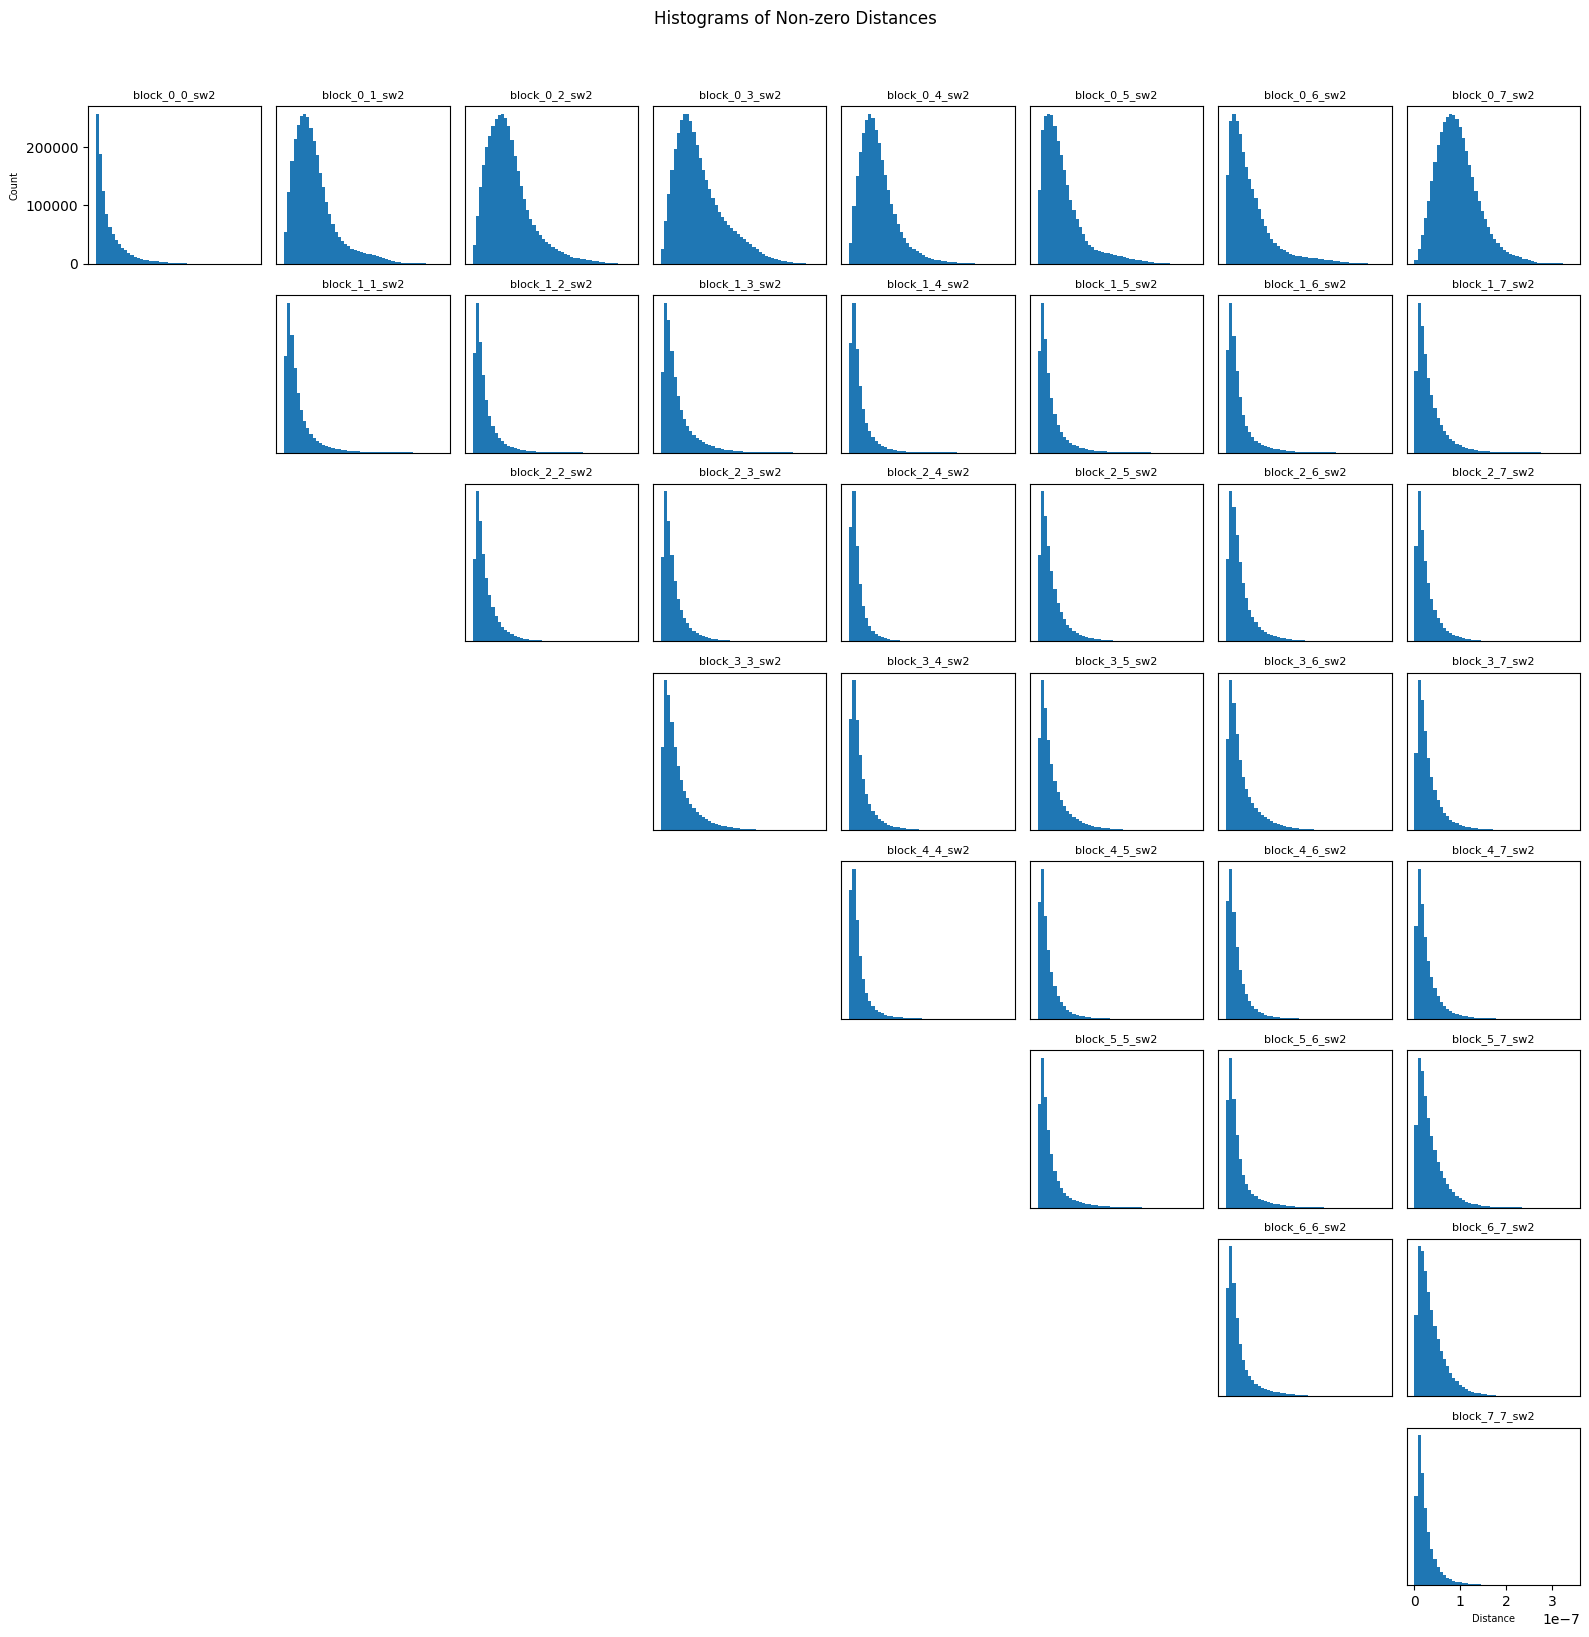

In [11]:
n = 8
fig, axes = plt.subplots(n, n, figsize=(16, 16))

for i in range(n):
    for j in range(n):
        ax = axes[i, j]
        if j >= i:
            # load the block_i_j matrix
            mat = np.load(f'block_{i}_{j}_sw2.npy')
            # extract non-zero entries
            data = mat[mat != 0]
            # plot histogram
            data /= 1000*1000
            ax.hist(data, bins=50)
            # set x-axis limits
            # ax.set_xlim(0, 8000)
            # ax.set_ylim(0, 200000)
            ax.set_title(f"block_{i}_{j}_sw2", fontsize=8)
            # only label bottom row
            if i == n - 1:
                ax.set_xlabel("Distance", fontsize=7)
            else:
                ax.set_xticks([])
            # only label first column
            if j == 0:
                ax.set_ylabel("Count", fontsize=7)
            else:
                ax.set_yticks([])
        else:
            # hide the lower-triangle axes
            ax.axis('off')

fig.suptitle("Histograms of Non-zero Distances", y=1.02)
fig.tight_layout()
plt.show()